# Gradient boosting regression of cortical bone modulus from chemical composition
E: modulus in GPa

Ca: calcium concentration in gm/gm

Vf: bone volume fraction (1-porosity)

Model: `sklearn.ensemble.GradientBoostingRegressor` — an additive ensemble of shallow regression trees, no physical form assumed

E ≈ F_M(Ca, Vf) = F_0 + ν·[h_1(Ca, Vf) + h_2(Ca, Vf) + … + h_M(Ca, Vf)]

F_0: mean E of the training data; h_m: regression tree fit to the residuals of the previous m−1 trees; ν: learning rate; M: number of trees

Hyperparameters (M, ν, tree depth, min samples per leaf, subsample fraction) are chosen by 5-fold cross-validation on the training data only

This version widens the grid for the number of trees to M = 20, 30, 40, 50, 75, 100, 200, 400 (previous notebook: 50, 100, 200, 400), so cross-validation can pick fewer than 50 trees\n\nExtra visualisation cells after the plotting block:\n1. Boosting in action: residual maps after 1, 5 and 20 trees, and the shrinking size of each tree's correction\n2. Partial dependence (average effect) and ICE curves for Ca and Vf, with the Currey model overlaid\n3. Residuals coloured by specimen group, and a learning curve (error vs number of training specimens)\n4. 90% prediction intervals from quantile gradient boosting, inside and outside the data range

Data to be imported is 'bone_composition_modulus_final'

Code is written to split the data into 75% fitting / 25% test (same shuffle and split as the Currey notebook)


In [1]:
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
from sklearn.ensemble import GradientBoostingRegressor
from sklearn.model_selection import GridSearchCV, KFold, GroupKFold, learning_curve, cross_val_score
from sklearn.inspection import PartialDependenceDisplay
from scipy.optimize import curve_fit

DATA = 'bone_composition_modulus_final.csv'
SEED, TEST_FRAC = 0, 0.25

GRID = {'n_estimators': [20, 30, 40, 50, 75, 100, 200, 400],
        'learning_rate': [0.01, 0.05, 0.1, 0.2],
        'max_depth': [1, 2, 3, 4],
        'min_samples_leaf': [1, 5, 10],
        'subsample': [0.7, 1.0]}

def metrics(obs, pred):
    r = obs - pred
    return dict(R2=1 - (r ** 2).sum() / ((obs - obs.mean()) ** 2).sum(),
                RMSE=np.sqrt((r ** 2).mean()), MAE=np.abs(r).mean(), bias=r.mean())

def fit_split(d, seed):
    idx = np.random.default_rng(seed).permutation(len(d))   # shuffle before splitting
    n_test = int(round(TEST_FRAC * len(d)))
    te, tr = d.iloc[idx[:n_test]], d.iloc[idx[n_test:]]
    X = lambda s: np.column_stack([s.Ca_mg_g.values / 1000, s.Vf.values])
    search = GridSearchCV(GradientBoostingRegressor(random_state=seed), GRID,
                          cv=KFold(5, shuffle=True, random_state=seed),
                          scoring='neg_root_mean_squared_error', n_jobs=-1)
    search.fit(X(tr), tr.E_GPa.values)                       # tuning uses training data only
    return tr, te, search, X

d = pd.read_csv(DATA).dropna(subset=['Ca_mg_g', 'Vf', 'E_GPa']).reset_index(drop=True)
tr, te, search, X = fit_split(d, SEED)
gbr, p = search.best_estimator_, search.best_params_
pred_tr, pred_te = gbr.predict(X(tr)), gbr.predict(X(te))
m_tr, m_te = metrics(tr.E_GPa.values, pred_tr), metrics(te.E_GPa.values, pred_te)

print(f'Data: {DATA}, n = {len(d)}: train {len(tr)}, test {len(te)}, shuffle seed {SEED}')
for n, v in p.items(): print(f'  {n} = {v}')
print(f'  5-fold CV RMSE = {-search.best_score_:.3f} ± {search.cv_results_["std_test_score"][search.best_index_]:.2g} GPa (training data)')
print(f'  feature importance: Ca = {gbr.feature_importances_[0]:.3f}, Vf = {gbr.feature_importances_[1]:.3f}')
print(pd.DataFrame({'train': m_tr, 'test': m_te}).round(3).to_string())

Data: bone_composition_modulus_final.csv, n = 369: train 277, test 92, shuffle seed 0
  learning_rate = 0.2
  max_depth = 2
  min_samples_leaf = 10
  n_estimators = 20
  subsample = 0.7
  5-fold CV RMSE = 3.935 ± 0.35 GPa (training data)
  feature importance: Ca = 0.693, Vf = 0.307
      train   test
R2    0.801  0.740
RMSE  3.474  4.092
MAE   2.670  3.023
bias  0.030  0.279


# CV RMSE by learning rate and number of trees
Best 5-fold CV RMSE (GPa, training data) over the other settings, for each learning rate × number of trees

In [2]:
cv = pd.DataFrame(search.cv_results_).assign(RMSE=lambda r: -r.mean_test_score)
tab = cv.pivot_table(index='param_learning_rate', columns='param_n_estimators', values='RMSE', aggfunc='min')
tab.index.name, tab.columns.name = 'learning_rate', 'n_estimators'
print(tab.round(3).to_string())
tab.to_csv('gbr_viz_cv_table.csv')

n_estimators     20     30     40     50     75     100    200    400
learning_rate                                                        
0.01           6.761  6.348  5.992  5.674  5.070  4.680  4.119  4.006
0.05           4.653  4.281  4.139  4.069  4.023  4.025  4.030  4.103
0.10           4.063  4.045  4.026  4.026  4.051  4.053  4.084  4.102
0.20           3.935  3.988  3.983  3.999  4.078  4.099  4.147  4.170


# Plotting block

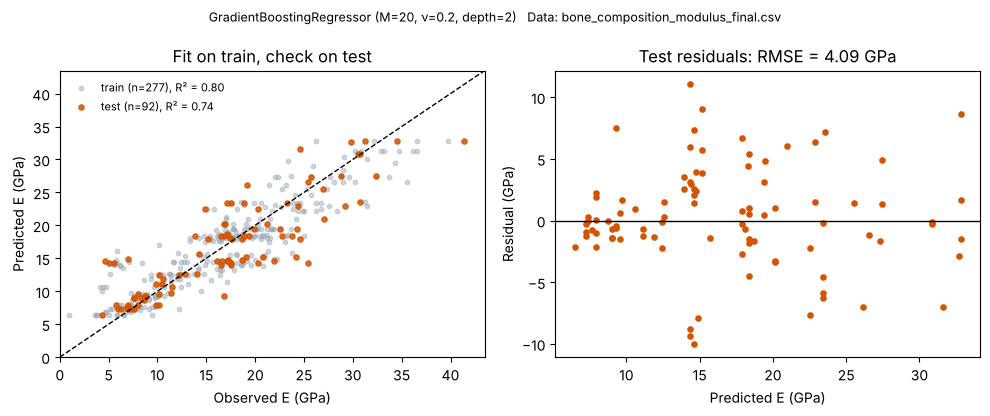

In [3]:
pd.DataFrame({'param': list(p) + ['cv_RMSE_GPa', 'importance_Ca', 'importance_Vf'],
              'value': list(p.values()) + [-search.best_score_, *gbr.feature_importances_]}) \
  .to_csv(f'gbr_viz_params.csv', index=False)
pd.concat([tr.assign(set='train', E_pred=pred_tr), te.assign(set='test', E_pred=pred_te)]) \
  .to_csv(f'gbr_viz_predictions.csv', index=False)

fig, ax = plt.subplots(1, 2, figsize=(10, 4.2))
lim = [0, max(d.E_GPa.max(), pred_tr.max()) * 1.05]
ax[0].scatter(tr.E_GPa, pred_tr, s=10, alpha=.45, color='#9aa7b5', label=f'train (n={len(tr)}), R² = {m_tr["R2"]:.2f}')
ax[0].scatter(te.E_GPa, pred_te, s=14, alpha=.85, color='#d35400', label=f'test (n={len(te)}), R² = {m_te["R2"]:.2f}')
ax[0].plot(lim, lim, 'k--', lw=1); ax[0].legend(frameon=False, fontsize=8)
ax[0].set(xlim=lim, ylim=lim, xlabel='Observed E (GPa)', ylabel='Predicted E (GPa)', title='Fit on train, check on test')
ax[1].scatter(pred_te, te.E_GPa - pred_te, s=14, color='#d35400'); ax[1].axhline(0, color='k', lw=1)
ax[1].set(xlabel='Predicted E (GPa)', ylabel='Residual (GPa)', title=f'Test residuals: RMSE = {m_te["RMSE"]:.2f} GPa')
fig.suptitle(f'GradientBoostingRegressor (M={p["n_estimators"]}, ν={p["learning_rate"]}, depth={p["max_depth"]})   Data: {DATA}', fontsize=9)
fig.tight_layout(); fig.savefig(f'gbr_viz.png', dpi=150)
plt.show()

# 1. Boosting in action
Each tree is fit to the residuals (measured E − current prediction) left by the trees before it.

Top: training specimens in the (Ca, Vf) plane coloured by their residual after 1, 5 and 20 trees. Large systematic red/blue regions mean structure the model has not yet captured; by the final tree what remains is a mix of colours with no clear pattern.

Bottom left: average size of each tree's correction, mean |ν·h_m(x)| over the training specimens. Corrections shrink as predictions improve.

Bottom right: training and test RMSE after each tree (`staged_predict`).

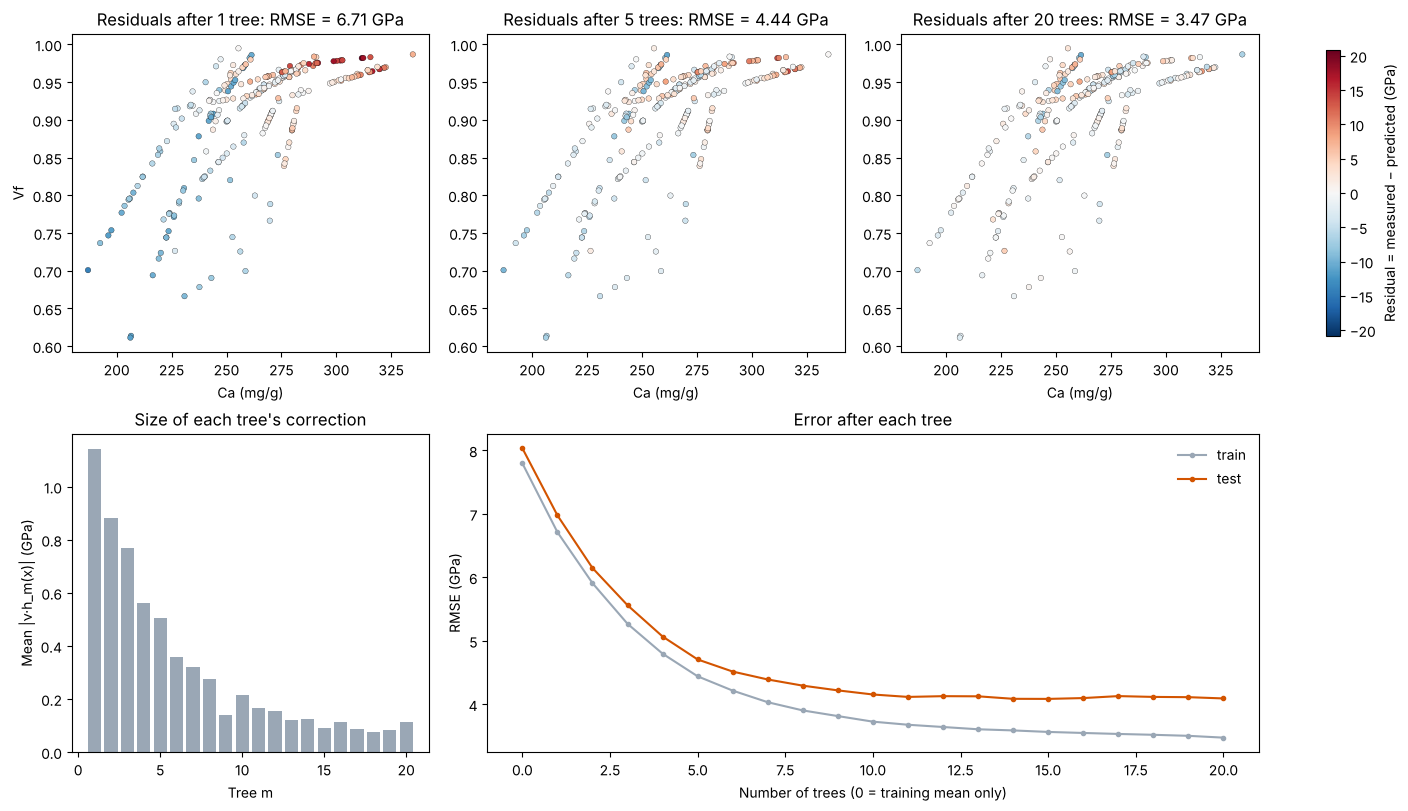

Correction size: tree 1 = 1.14 GPa, tree 20 = 0.11 GPa


In [4]:
Xtr, ytr, Xte, yte = X(tr), tr.E_GPa.values, X(te), te.E_GPa.values
stages_tr = np.array(list(gbr.staged_predict(Xtr)))
stages_te = np.array(list(gbr.staged_predict(Xte)))
M = p['n_estimators']
show = [1, 5, M]
lim = np.abs(ytr - stages_tr[0]).max()

fig, A = plt.subplot_mosaic([['r0', 'r1', 'r2'], ['bar', 'err', 'err']], figsize=(14, 8), layout='constrained')
for j, m in enumerate(show):
    a = A[f'r{j}']
    res = ytr - stages_tr[m - 1]
    sc = a.scatter(Xtr[:, 0] * 1000, Xtr[:, 1], c=res, cmap='RdBu_r', vmin=-lim, vmax=lim, s=16, edgecolor='k', lw=.2)
    a.set(xlabel='Ca (mg/g)', ylabel='Vf' if j == 0 else '',
          title=f'Residuals after {m} tree{"s" if m > 1 else ""}: RMSE = {np.sqrt((res ** 2).mean()):.2f} GPa')
fig.colorbar(sc, ax=[A['r0'], A['r1'], A['r2']], label='Residual = measured − predicted (GPa)', shrink=.9)

step = [np.abs(p['learning_rate'] * t[0].predict(Xtr)).mean() for t in gbr.estimators_]
a = A['bar']
a.bar(range(1, M + 1), step, color='#9aa7b5'); a.set(xlabel='Tree m', ylabel='Mean |ν·h_m(x)| (GPa)', title='Size of each tree\'s correction')
a = A['err']
rm = lambda y, P: np.sqrt(((P - y) ** 2).mean(axis=1))
a.plot(range(0, M + 1), np.r_[ytr.std(), rm(ytr, stages_tr)], 'o-', ms=3, color='#9aa7b5', label='train')
a.plot(range(0, M + 1), np.r_[np.sqrt(((yte - ytr.mean()) ** 2).mean()), rm(yte, stages_te)], 'o-', ms=3, color='#d35400', label='test')
a.set(xlabel='Number of trees (0 = training mean only)', ylabel='RMSE (GPa)', title='Error after each tree'); a.legend(frameon=False)
fig.savefig('gbr_viz_boosting.png', dpi=150)
plt.show()
print(f'Correction size: tree 1 = {step[0]:.2f} GPa, tree {M} = {step[-1]:.2f} GPa')

# 2. What the model learned about Ca and Vf, compared with Currey
Partial dependence (thick line): the model's average prediction as one input is varied, averaging over the training values of the other input.

ICE curves (thin lines): the same, but for individual training specimens; spread between them shows the effect of the other input (interaction).

Currey's model E = k·Ca^x·Vf^y is fit to the same training data with `curve_fit` and drawn with the other input at its training median.

Currey fit on the same training data: k = 572.7 GPa, x = 2.505, y = 2.300


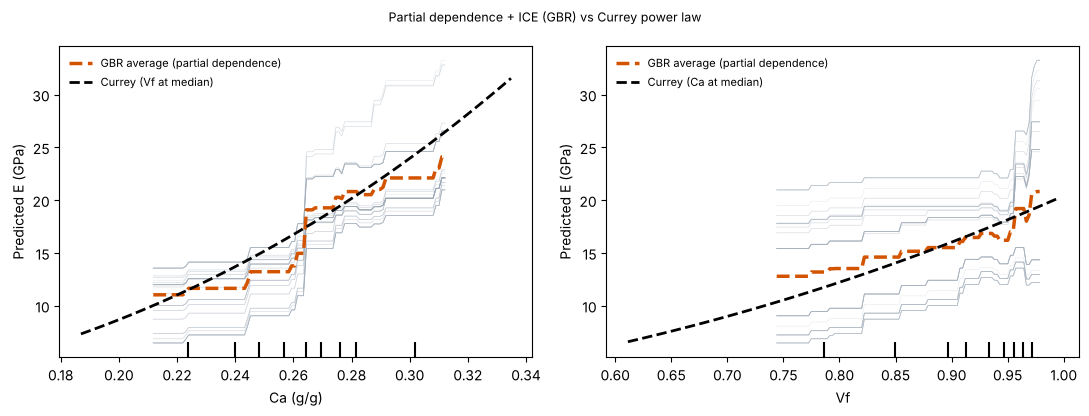

In [5]:
currey = lambda Xc, k, x, y: k * Xc[0] ** x * Xc[1] ** y
pc, _ = curve_fit(currey, (Xtr[:, 0], Xtr[:, 1]), ytr, p0=[500, 2, 3], maxfev=20000)
print('Currey fit on the same training data: k = %.1f GPa, x = %.3f, y = %.3f' % tuple(pc))

fig, ax = plt.subplots(1, 2, figsize=(11, 4.2))
PartialDependenceDisplay.from_estimator(gbr, Xtr, [0, 1], feature_names=['Ca (g/g)', 'Vf'], kind='both',
                                        subsample=60, random_state=SEED, ax=ax,
                                        ice_lines_kw={'alpha': .2, 'color': '#9aa7b5'},
                                        pd_line_kw={'color': '#d35400', 'lw': 2.5, 'label': 'GBR average (partial dependence)'})
ca_g = np.linspace(Xtr[:, 0].min(), Xtr[:, 0].max(), 100)
vf_g = np.linspace(Xtr[:, 1].min(), Xtr[:, 1].max(), 100)
fig.axes[0].plot(ca_g, currey((ca_g, np.median(Xtr[:, 1])), *pc), 'k--', lw=2, label='Currey (Vf at median)')
fig.axes[1].plot(vf_g, currey((np.median(Xtr[:, 0]), vf_g), *pc), 'k--', lw=2, label='Currey (Ca at median)')
for a in fig.axes[:2]:
    a.set_ylabel('Predicted E (GPa)'); a.legend(frameon=False, fontsize=8)
fig.suptitle('Partial dependence + ICE (GBR) vs Currey power law', fontsize=9)
fig.tight_layout(); fig.savefig('gbr_viz_partial_dependence.png', dpi=150)
plt.show()

# 3. Why the error levels off: specimen groups, and more data
The data set has no group column, but each block of ~20 consecutive `source_row` values follows its own exact power law in `E_GPa_original` (log-linear R² ≈ 1.000 within a block), so those blocks are used here as specimen groups.

Left: residuals of the tuned model vs Ca and vs Vf, coloured by group (circles = train, triangles = test). If residuals cluster by colour, groups differ in stiffness at the same composition, which Ca and Vf alone cannot explain.

Right: learning curve, i.e. CV RMSE vs number of training specimens (`learning_curve`). A curve that is still falling means more data would help; a flat curve means it would not.

Also printed: CV RMSE when whole groups are held out (`GroupKFold`), an estimate for specimens from a group the model has never seen.

Mean residual by group (GPa):
0    -1.91
1     0.76
2    -1.42
3    -3.31
4    -7.94
5     3.87
6     4.17
7     1.02
8     2.26
9    -0.01
10   -3.11
11    2.87
12    0.57
13    4.66
14   -0.98
15   -1.46
16    1.27
17   -2.44
18    2.59
Share of residual variance explained by group: 0.68


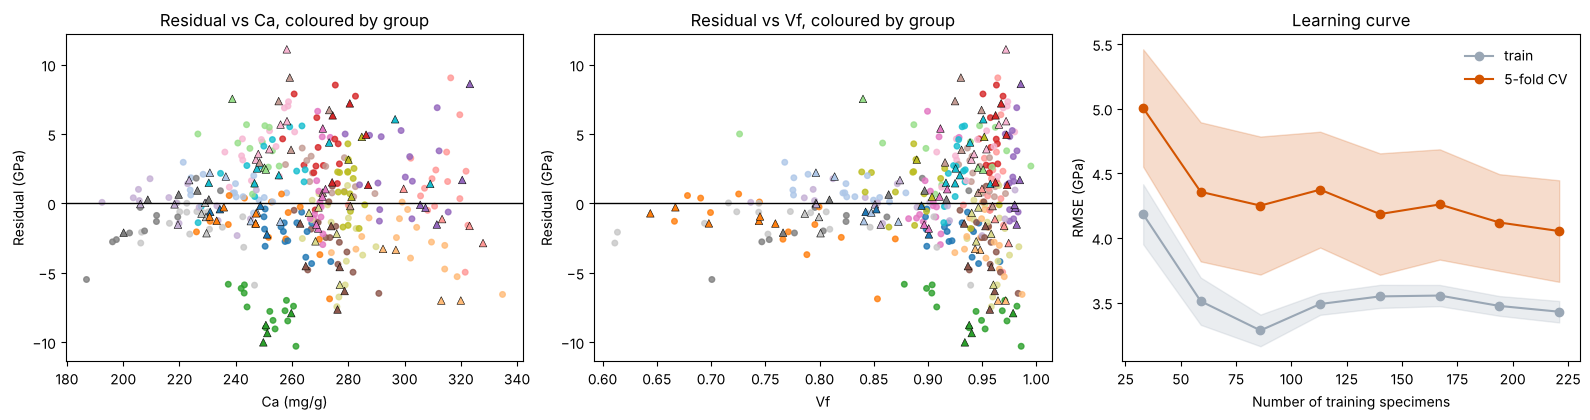


CV RMSE, random folds (KFold): 3.93 GPa   |   whole groups held out (GroupKFold): 5.31 GPa


In [6]:
EDGES = [3, 24, 45, 66, 85, 105, 125, 145, 165, 185, 205, 225, 245, 265, 285, 305, 325, 345, 365, 400]
group = lambda s: np.digitize(s.source_row.values, EDGES) - 1
g_tr, g_te = group(tr), group(te)
res_tr, res_te = ytr - pred_tr, yte - pred_te
cmap = plt.get_cmap('tab20')

fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
for a, col, lab in [(ax[0], 0, 'Ca (mg/g)'), (ax[1], 1, 'Vf')]:
    sc = 1000 if col == 0 else 1
    a.scatter(Xtr[:, col] * sc, res_tr, c=g_tr, cmap=cmap, vmin=0, vmax=19, s=16, marker='o', alpha=.8)
    a.scatter(Xte[:, col] * sc, res_te, c=g_te, cmap=cmap, vmin=0, vmax=19, s=30, marker='^', edgecolor='k', lw=.4)
    a.axhline(0, color='k', lw=1); a.set(xlabel=lab, ylabel='Residual (GPa)', title=f'Residual vs {lab.split()[0]}, coloured by group')

g_all = np.r_[g_tr, g_te]; r_all = np.r_[res_tr, res_te]
by_g = pd.Series(r_all).groupby(g_all).mean()
print('Mean residual by group (GPa):'); print(by_g.round(2).to_string())
print(f'Share of residual variance explained by group: {np.var(by_g.reindex(g_all).values) / np.var(r_all):.2f}')

sizes, tr_sc, cv_sc = learning_curve(GradientBoostingRegressor(random_state=SEED, **p), Xtr, ytr,
                                     train_sizes=np.linspace(.15, 1, 8), cv=KFold(5, shuffle=True, random_state=SEED),
                                     scoring='neg_root_mean_squared_error', n_jobs=-1)
for sc_, c, lab in [(-tr_sc, '#9aa7b5', 'train'), (-cv_sc, '#d35400', '5-fold CV')]:
    ax[2].plot(sizes, sc_.mean(1), 'o-', color=c, label=lab)
    ax[2].fill_between(sizes, sc_.mean(1) - sc_.std(1), sc_.mean(1) + sc_.std(1), color=c, alpha=.2)
ax[2].set(xlabel='Number of training specimens', ylabel='RMSE (GPa)', title='Learning curve'); ax[2].legend(frameon=False)
fig.tight_layout(); fig.savefig('gbr_viz_groups_learning_curve.png', dpi=150)
plt.show()

kf = -cross_val_score(GradientBoostingRegressor(random_state=SEED, **p), Xtr, ytr,
                      cv=KFold(5, shuffle=True, random_state=SEED), scoring='neg_root_mean_squared_error').mean()
gk = -cross_val_score(GradientBoostingRegressor(random_state=SEED, **p), Xtr, ytr, groups=g_tr,
                      cv=GroupKFold(5), scoring='neg_root_mean_squared_error').mean()
print(f'\nCV RMSE, random folds (KFold): {kf:.2f} GPa   |   whole groups held out (GroupKFold): {gk:.2f} GPa')

# 4. Prediction intervals, inside and outside the data range
Two extra models are fit with `loss='quantile'` (alpha = 0.05 and 0.95) and the same tuned settings; together they give a 90% prediction interval. The leaf values become quantiles of the residuals instead of means.

Coverage on the 92 test specimens is printed (ideal ≈ 90%).

Plots: predictions along Ca (Vf fixed at its median) and along Vf (Ca fixed at its median), extended well beyond the data (grey band). Outside the data the GBR prediction and its interval go flat; Currey keeps following its power law.

90% interval coverage on test: 88%   mean width: 13.5 GPa


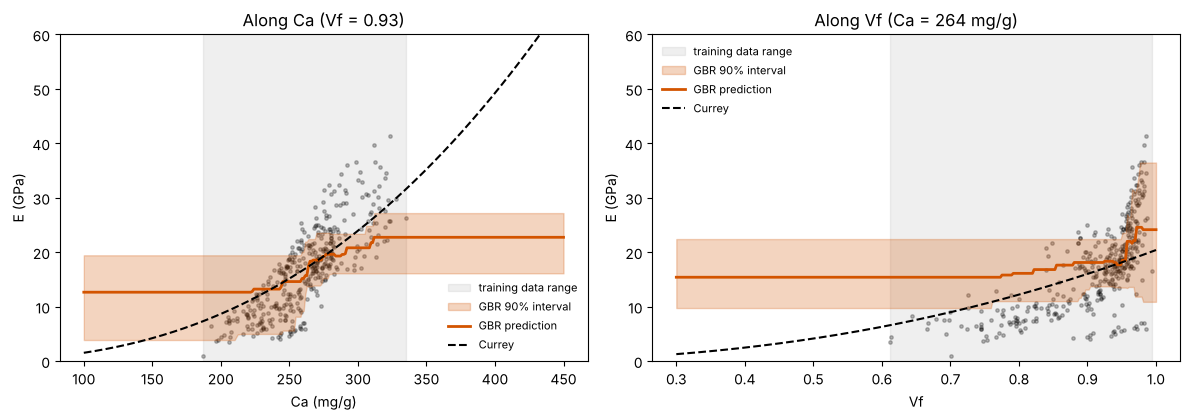

In [7]:
q = {a: GradientBoostingRegressor(loss='quantile', alpha=a, random_state=SEED, **p).fit(Xtr, ytr) for a in (0.05, 0.95)}
lo, hi = q[0.05].predict(Xte), q[0.95].predict(Xte)
print(f'90% interval coverage on test: {np.mean((yte >= lo) & (yte <= hi)) * 100:.0f}%   mean width: {np.mean(hi - lo):.1f} GPa')

vf_med, ca_med = np.median(Xtr[:, 1]), np.median(Xtr[:, 0])
ca_x = np.linspace(0.10, 0.45, 300); vf_x = np.linspace(0.30, 1.00, 300)
fig, ax = plt.subplots(1, 2, figsize=(12, 4.3))
for a, grid, other, col, lab, sc in [(ax[0], ca_x, vf_med, 0, 'Ca (mg/g)', 1000), (ax[1], vf_x, ca_med, 1, 'Vf', 1)]:
    G = np.c_[grid, np.full_like(grid, other)] if col == 0 else np.c_[np.full_like(grid, other), grid]
    a.axvspan(Xtr[:, col].min() * sc, Xtr[:, col].max() * sc, color='grey', alpha=.12, label='training data range')
    a.scatter(np.r_[Xtr[:, col], Xte[:, col]] * sc, np.r_[ytr, yte], s=6, color='k', alpha=.25)
    a.fill_between(grid * sc, q[0.05].predict(G), q[0.95].predict(G), color='#d35400', alpha=.25, label='GBR 90% interval')
    a.plot(grid * sc, gbr.predict(G), color='#d35400', lw=2, label='GBR prediction')
    a.plot(grid * sc, currey((G[:, 0], G[:, 1]), *pc), 'k--', lw=1.5, label='Currey')
    other_lab = f'Vf = {other:.2f}' if col == 0 else f'Ca = {other * 1000:.0f} mg/g'
    a.set(xlabel=lab, ylabel='E (GPa)', title=f'Along {lab.split()[0]} ({other_lab})', ylim=(0, 60)); a.legend(frameon=False, fontsize=8)
fig.tight_layout(); fig.savefig('gbr_viz_prediction_intervals.png', dpi=150)
plt.show()